In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/kchouse_processeddata.csv")

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Basic Data Inspection

In [10]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_living15,sqft_lot15,sale_year,sale_month,sale_quarter,property_age,is_renovated,years_since_renovation,price_per_sqft_living,price_per_sqft_lot
0,7129300520,2014-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,...,1340,5650,2014,10,4,59,0,0,188.050847,39.274336
1,6414100192,2014-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,...,1690,7639,2014,12,4,63,1,23,209.338521,74.288870
2,5631500400,2015-02-25,180000.0,2,1.00,770,10000,1.0,0,0,...,2720,8062,2015,2,1,82,0,0,233.766234,18.000000
3,2487200875,2014-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,...,1360,5000,2014,12,4,49,0,0,308.163265,120.800000
4,1954400510,2015-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,...,1800,7503,2015,2,1,28,0,0,303.571429,63.118812


In [11]:
df.tail()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_living15,sqft_lot15,sale_year,sale_month,sale_quarter,property_age,is_renovated,years_since_renovation,price_per_sqft_living,price_per_sqft_lot
21592,263000018,2014-05-21,360000.0,3,2.50,1530,1131,3.0,0,0,...,1530,1509,2014,5,2,5,0,0,235.294118,318.302387
21593,6600060120,2015-02-23,400000.0,4,2.50,2310,5813,2.0,0,0,...,1830,7200,2015,2,1,1,0,0,173.160173,68.811285
21594,1523300141,2014-06-23,402101.0,2,0.75,1020,1350,2.0,0,0,...,1020,2007,2014,6,2,5,0,0,394.216667,297.852593
21595,291310100,2015-01-16,400000.0,3,2.50,1600,2388,2.0,0,0,...,1410,1287,2015,1,1,11,0,0,250.000000,167.504188
21596,1523300157,2014-10-15,325000.0,2,0.75,1020,1076,2.0,0,0,...,1020,1357,2014,10,4,6,0,0,318.627451,302.044610


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      21597 non-null  int64  
 1   date                    21597 non-null  object 
 2   price                   21597 non-null  float64
 3   bedrooms                21597 non-null  int64  
 4   bathrooms               21597 non-null  float64
 5   sqft_living             21597 non-null  int64  
 6   sqft_lot                21597 non-null  int64  
 7   floors                  21597 non-null  float64
 8   waterfront              21597 non-null  int64  
 9   view                    21597 non-null  int64  
 10  condition               21597 non-null  int64  
 11  grade                   21597 non-null  int64  
 12  sqft_above              21597 non-null  int64  
 13  sqft_basement           21597 non-null  int64  
 14  yr_built                21597 non-null

In [13]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_living15,sqft_lot15,sale_year,sale_month,sale_quarter,property_age,is_renovated,years_since_renovation,price_per_sqft_living,price_per_sqft_lot
count,2.159700e+04,2.159700e+04,21597.000000,21597.000000,21597.000000,2.159700e+04,21597.000000,21597.000000,21597.000000,21597.000000,...,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000,21597.000000
mean,4.580474e+09,5.402029e+05,3.373200,2.115826,2080.321850,1.509941e+04,1.494096,0.007547,0.234292,3.409825,...,1986.620318,12758.283512,2014.322962,6.573969,2.524656,43.323286,0.042321,0.780525,264.116293,88.978283
std,2.876736e+09,3.671337e+05,0.926299,0.768984,918.106125,4.141264e+04,0.539683,0.086549,0.766390,0.650546,...,685.230472,27274.441950,0.467619,3.115061,1.034148,29.377285,0.201324,4.897097,109.960335,94.048993
min,1.000102e+06,7.800000e+04,1.000000,0.500000,370.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,399.000000,651.000000,2014.000000,1.000000,1.000000,-1.000000,0.000000,-1.000000,87.588235,0.163119
25%,2.123049e+09,3.220000e+05,3.000000,1.750000,1430.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,...,1490.000000,5100.000000,2014.000000,4.000000,2.000000,18.000000,0.000000,0.000000,182.291667,33.333333
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,...,1840.000000,7620.000000,2014.000000,6.000000,2.000000,40.000000,0.000000,0.000000,244.644550,59.259259
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068500e+04,2.000000,0.000000,0.000000,4.000000,...,2360.000000,10083.000000,2015.000000,9.000000,3.000000,63.000000,0.000000,0.000000,318.313953,107.609372
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,...,6210.000000,871200.000000,2015.000000,12.000000,4.000000,115.000000,1.000000,80.000000,810.138889,2027.208539


In [14]:
df.shape

(21597, 29)

In [15]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month',
       'sale_quarter', 'property_age', 'is_renovated',
       'years_since_renovation', 'price_per_sqft_living',
       'price_per_sqft_lot'],
      dtype='object')

## 2. Living Area and House Price Analy

In [16]:
correlation = df["sqft_living"].corr(df["price"])

print("Correlation between sqft_living and price:", correlation)

Correlation between sqft_living and price: 0.7019092759952941


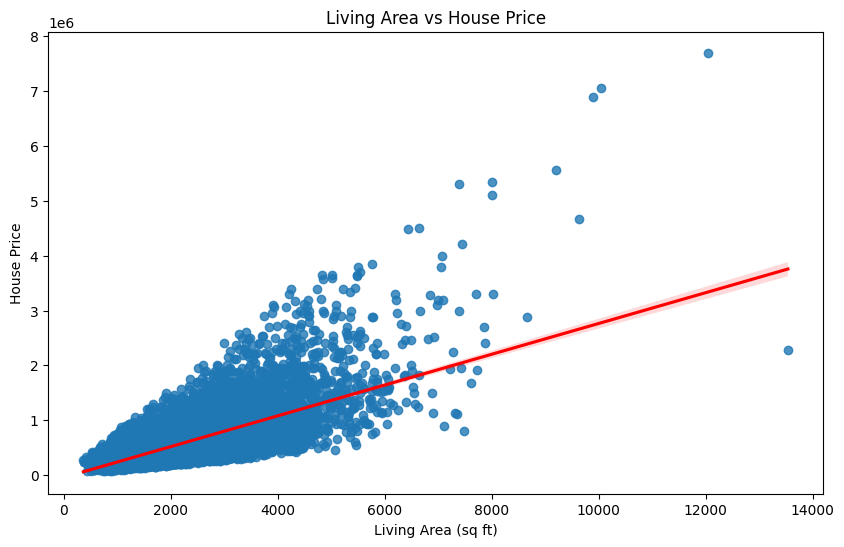

In [17]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x="sqft_living",
    y="price",
    data=df,
    line_kws={"color": "red"}
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("House Price")
plt.show()

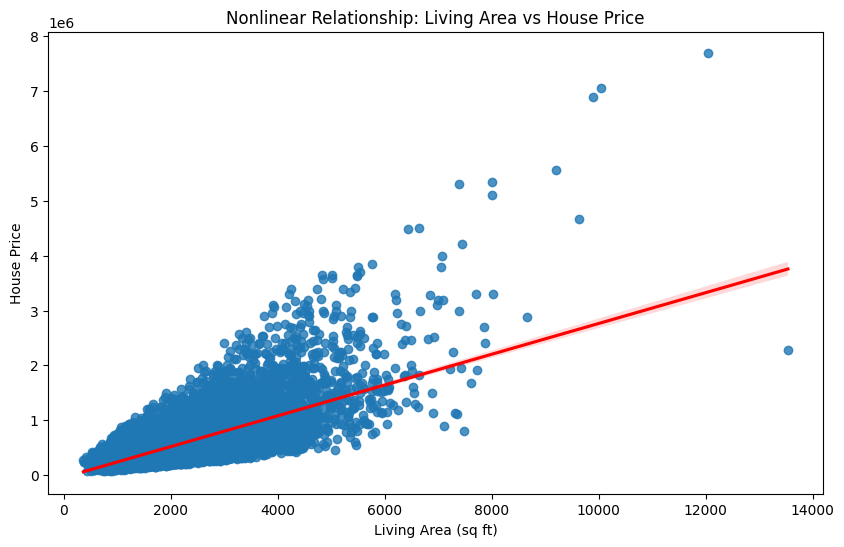

In [18]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x="sqft_living",
    y="price",
    data=df,
    line_kws={"color": "red"}
)

plt.title("Nonlinear Relationship: Living Area vs House Price")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("House Price")
plt.show()

In [19]:
Q1 = df["price_per_sqft_living"].quantile(0.25)
Q3 = df["price_per_sqft_living"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

unusual_properties = df[
    (df["price_per_sqft_living"] < lower_bound) |
    (df["price_per_sqft_living"] > upper_bound)
]

print("Number of unusual properties:", len(unusual_properties))

unusual_properties[
    ["price", "sqft_living", "price_per_sqft_living"]
].head(10)

Number of unusual properties: 705


,price,sqft_living,price_per_sqft_living
21,2000000.0,3050,655.737705
125,1450000.0,2750,527.272727
140,665000.0,1110,599.099099
246,2400000.0,3650,657.534247
263,425000.0,770,551.948052
269,2900000.0,5050,574.257426
282,2050000.0,3830,535.248042
300,3075000.0,4550,675.824176
308,550700.0,1010,545.247525
312,2384000.0,3650,653.150685


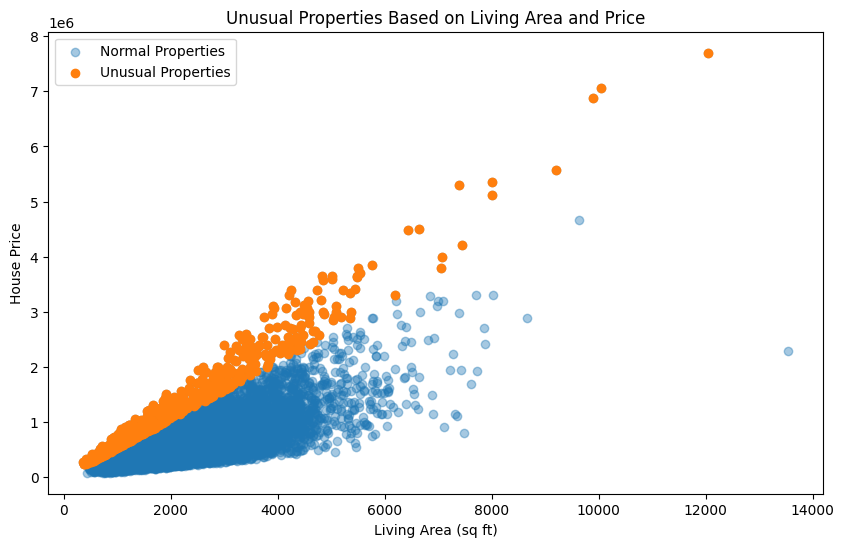

In [20]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["sqft_living"],
    df["price"],
    alpha=0.4,
    label="Normal Properties"
)

plt.scatter(
    unusual_properties["sqft_living"],
    unusual_properties["price"],
    label="Unusual Properties"
)

plt.xlabel("Living Area (sq ft)")
plt.ylabel("House Price")
plt.title("Unusual Properties Based on Living Area and Price")
plt.legend()
plt.show()

## 3.Property Grade and Condition Analysis

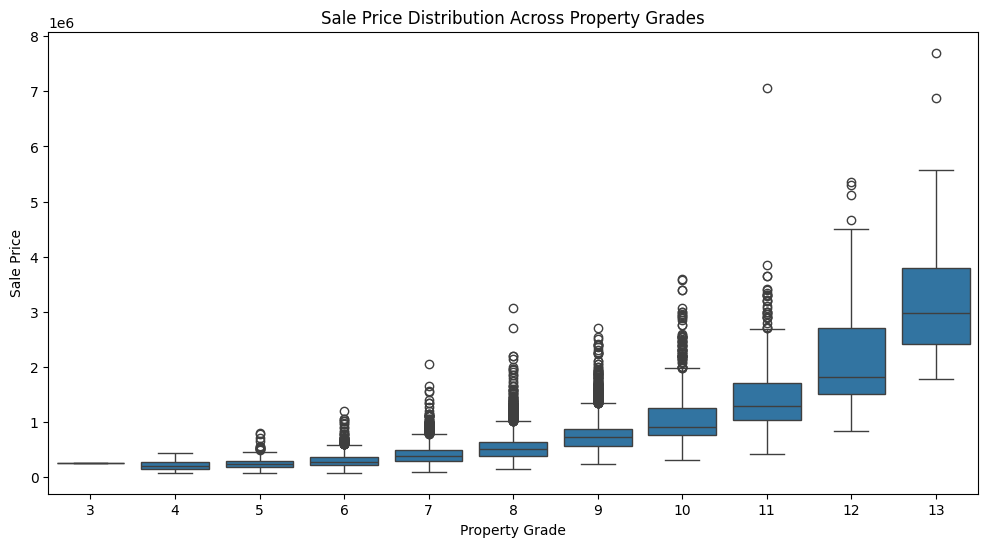

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x="grade",
    y="price",
    data=df
)

plt.title("Sale Price Distribution Across Property Grades")
plt.xlabel("Property Grade")
plt.ylabel("Sale Price")
plt.show()

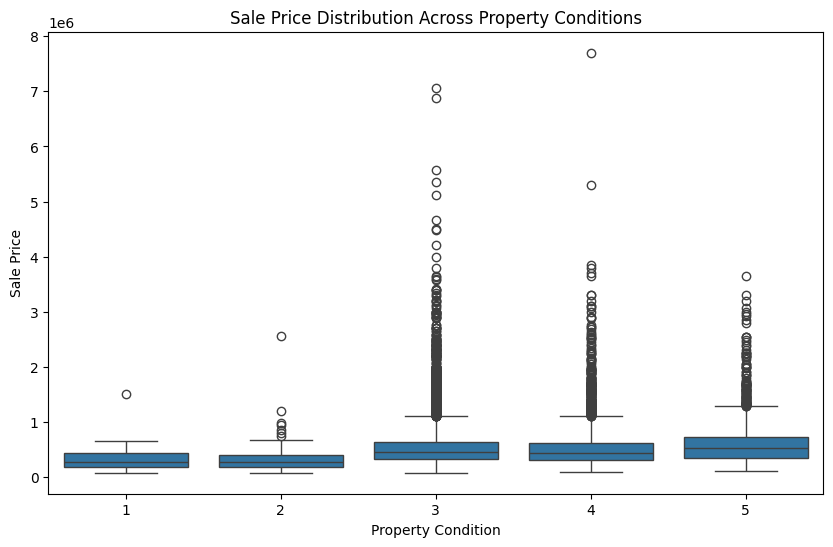

In [22]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="condition",
    y="price",
    data=df
)

plt.title("Sale Price Distribution Across Property Conditions")
plt.xlabel("Property Condition")
plt.ylabel("Sale Price")
plt.show()

In [23]:
grade_median = df.groupby("grade")["price"].median().sort_values()

print("Median Sale Price by Grade:")
print(grade_median)

Median Sale Price by Grade:
grade
4      200000.0
5      228700.0
3      262000.0
6      275276.5
7      375000.0
8      510000.0
9      720000.0
10     914327.0
11    1284000.0
12    1820000.0
13    2983000.0
Name: price, dtype: float64


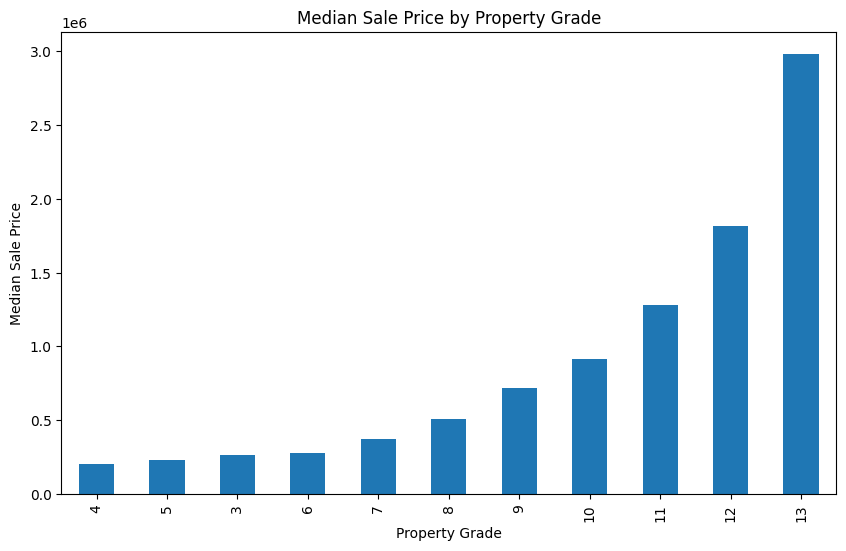

In [24]:
plt.figure(figsize=(10, 6))

grade_median.plot(kind="bar")

plt.title("Median Sale Price by Property Grade")
plt.xlabel("Property Grade")
plt.ylabel("Median Sale Price")
plt.show()

In [25]:
condition_median = df.groupby("condition")["price"].median().sort_values()

print("Median Sale Price by Condition:")
print(condition_median)

Median Sale Price by Condition:
condition
1    270000.0
2    279000.0
4    440000.0
3    450250.0
5    526000.0
Name: price, dtype: float64


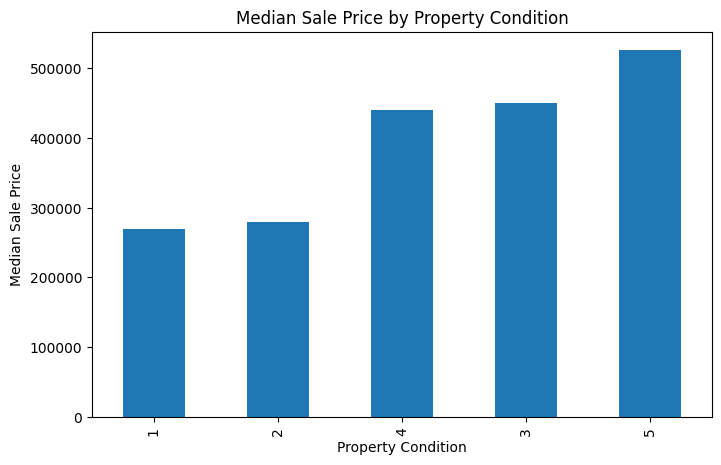

In [26]:
plt.figure(figsize=(8, 5))

condition_median.plot(kind="bar")

plt.title("Median Sale Price by Property Condition")
plt.xlabel("Property Condition")
plt.ylabel("Median Sale Price")
plt.show()

In [27]:
grade_variation = df.groupby("grade")["price"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

grade_variation

,count,mean,median,std,min,max
grade,,,,,,
3,1,2.620000e+05,262000.0,NaN,262000.0,262000.0
4,27,2.120019e+05,200000.0,9.729450e+04,80000.0,435000.0
5,242,2.485240e+05,228700.0,1.181003e+05,78000.0,795000.0
6,2038,3.019196e+05,275276.5,1.229703e+05,82000.0,1200000.0
7,8974,4.025921e+05,375000.0,1.557126e+05,90000.0,2050000.0
8,6065,5.429440e+05,510000.0,2.174881e+05,140000.0,3070000.0
9,2615,7.735132e+05,720000.0,3.161201e+05,230000.0,2700000.0
10,1134,1.071771e+06,914327.0,4.835451e+05,316000.0,3600000.0
11,399,1.496842e+06,1284000.0,7.050993e+05,420000.0,7062500.0


In [28]:
condition_variation = df.groupby("condition")["price"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

condition_variation

,count,mean,median,std,min,max
condition,,,,,,
1,29,341067.241379,270000.0,273482.773771,78000.0,1500000.0
2,170,328149.347059,279000.0,246719.822800,80000.0,2555000.0
3,14020,542089.150071,450250.0,364438.399052,82000.0,7062500.0
4,5677,521274.099877,440000.0,358543.332183,89000.0,7700000.0
5,1701,612418.089359,526000.0,410971.922540,110000.0,3650000.0


In [29]:
def find_outliers(group):
    Q1 = group["price"].quantile(0.25)
    Q3 = group["price"].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return group[
        (group["price"] < lower) |
        (group["price"] > upper)
    ]

grade_outliers = (
    df.groupby("grade", group_keys=False)
      .apply(find_outliers)
)

print("Number of grade-based outliers:", len(grade_outliers))

grade_outliers[
    ["grade", "condition", "price", "sqft_living"]
].head(10)

Number of grade-based outliers: 678


/tmp/ipykernel_845/2151553875.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(find_outliers)


,grade,condition,price,sqft_living
36,5,1,550000.0,1660
411,5,3,517534.0,833
700,5,3,795000.0,1380
4386,5,3,527550.0,820
5587,5,3,510000.0,820
5588,5,3,489950.0,820
8050,5,4,550000.0,1270
8597,5,3,533050.0,910
14042,5,3,510000.0,680
14085,5,4,715000.0,1000


In [30]:
grade_condition = df.pivot_table(
    values="price",
    index="grade",
    columns="condition",
    aggfunc="median"
)

grade_condition

condition,1,2,3,4,5
grade,,,,,
3,NaN,NaN,NaN,NaN,262000.0
4,150000.0,132500.0,196500.0,238525.0,NaN
5,190000.0,180000.0,234475.0,229975.0,227450.0
6,255000.0,235000.0,265000.0,295000.0,285475.0
7,403500.0,305000.0,357950.0,390000.0,456000.0
8,932500.0,429000.0,485000.0,571250.0,696000.0
9,NaN,715000.0,689000.0,823500.0,1078000.0
10,NaN,1752500.0,890000.0,1030000.0,1650000.0
11,NaN,NaN,1209500.0,1685000.0,2050000.0


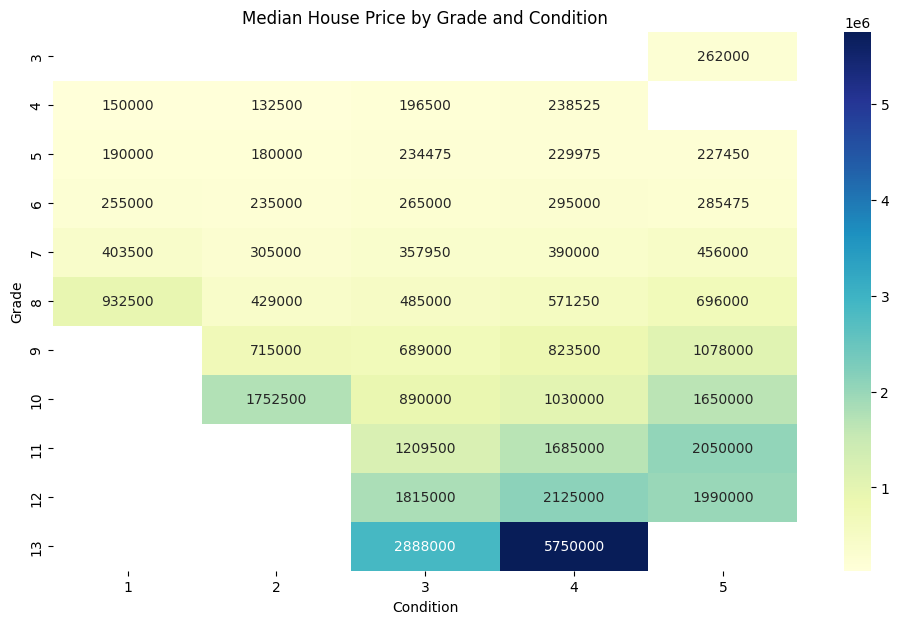

In [31]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    grade_condition,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Median House Price by Grade and Condition")
plt.xlabel("Condition")
plt.ylabel("Grade")
plt.show()

## 4. Waterfront Price Premium Analysis

In [32]:
waterfront_summary = df.groupby("waterfront")["price"].agg(
    ["count", "mean", "median", "std"]
)

waterfront_summary


,count,mean,median,std
waterfront,,,,
0,21434,5.316729e+05,450000.0,3.415897e+05
1,163,1.661876e+06,1400000.0,1.120372e+06


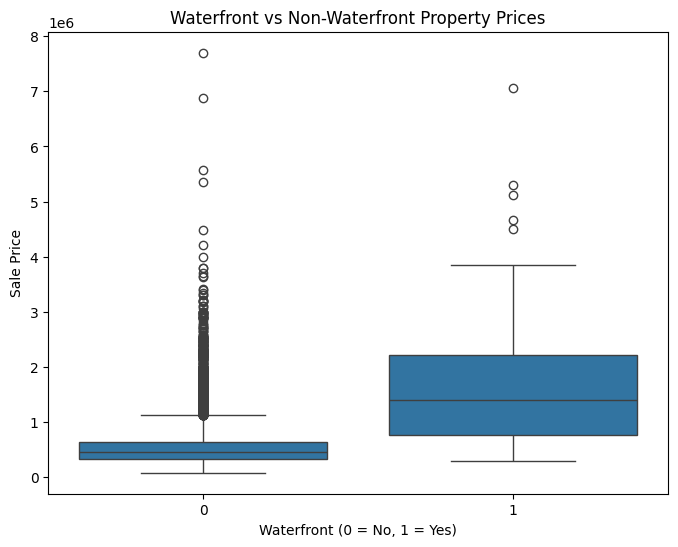

In [33]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x="waterfront",
    y="price",
    data=df
)

plt.title("Waterfront vs Non-Waterfront Property Prices")
plt.xlabel("Waterfront (0 = No, 1 = Yes)")
plt.ylabel("Sale Price")
plt.show()


In [34]:
waterfront_price = df[df["waterfront"] == 1]["price"]
non_waterfront_price = df[df["waterfront"] == 0]["price"]

mean_difference = waterfront_price.mean() - non_waterfront_price.mean()
median_difference = waterfront_price.median() - non_waterfront_price.median()

mean_premium = (
    (waterfront_price.mean() / non_waterfront_price.mean()) - 1
) * 100

median_premium = (
    (waterfront_price.median() / non_waterfront_price.median()) - 1
) * 100

print("Mean Price Difference:", mean_difference)
print("Median Price Difference:", median_difference)
print("Observed Mean Waterfront Premium:", round(mean_premium, 2), "%")
print("Observed Median Waterfront Premium:", round(median_premium, 2), "%")


Mean Price Difference: 1130203.1372579886
Median Price Difference: 950000.0
Observed Mean Waterfront Premium: 212.57 %
Observed Median Waterfront Premium: 211.11 %


In [35]:
df.groupby("waterfront").agg(
    average_price=("price", "mean"),
    average_living_area=("sqft_living", "mean"),
    average_grade=("grade", "mean"),
    average_condition=("condition", "mean")
)

,average_price,average_living_area,average_grade,average_condition
waterfront,,,,
0,5.316729e+05,2072.007092,7.649435,3.408883
1,1.661876e+06,3173.687117,8.773006,3.533742


## 5. Geographic House Price Analysis

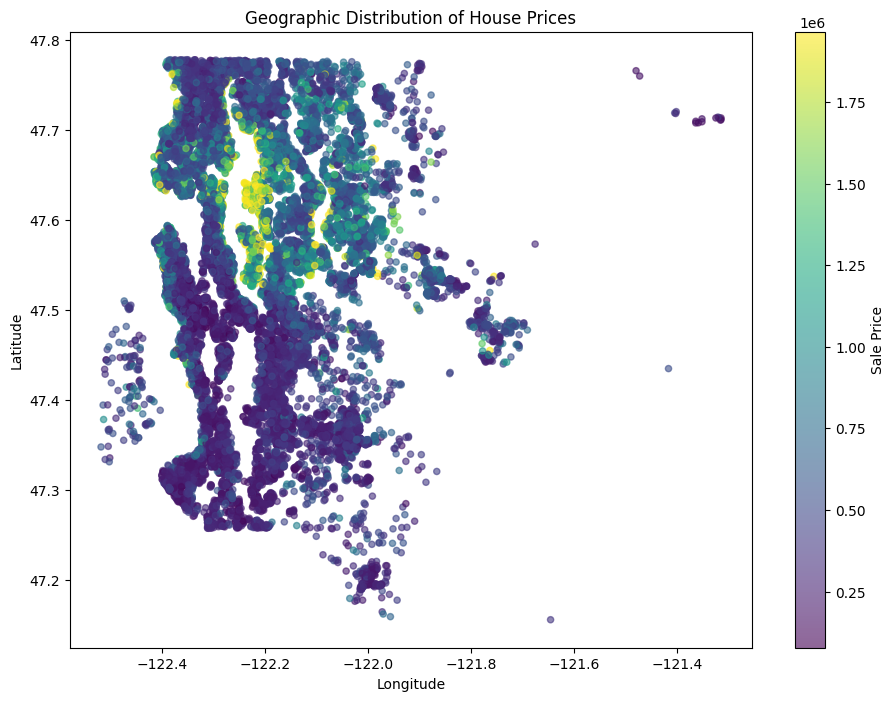

In [36]:
price_cap = df["price"].quantile(0.99)

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    df["long"],
    df["lat"],
    c=df["price"].clip(upper=price_cap),
    alpha=0.6,
    s=20
)

plt.colorbar(scatter, label="Sale Price")
plt.title("Geographic Distribution of House Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [37]:
high_value_threshold = df["price"].quantile(0.90)
df["high_value"] = df["price"] >= high_value_threshold

print("High-value threshold (90th percentile):", high_value_threshold)
print("Number of high-value properties:", df["high_value"].sum())


High-value threshold (90th percentile): 887000.0
Number of high-value properties: 2161


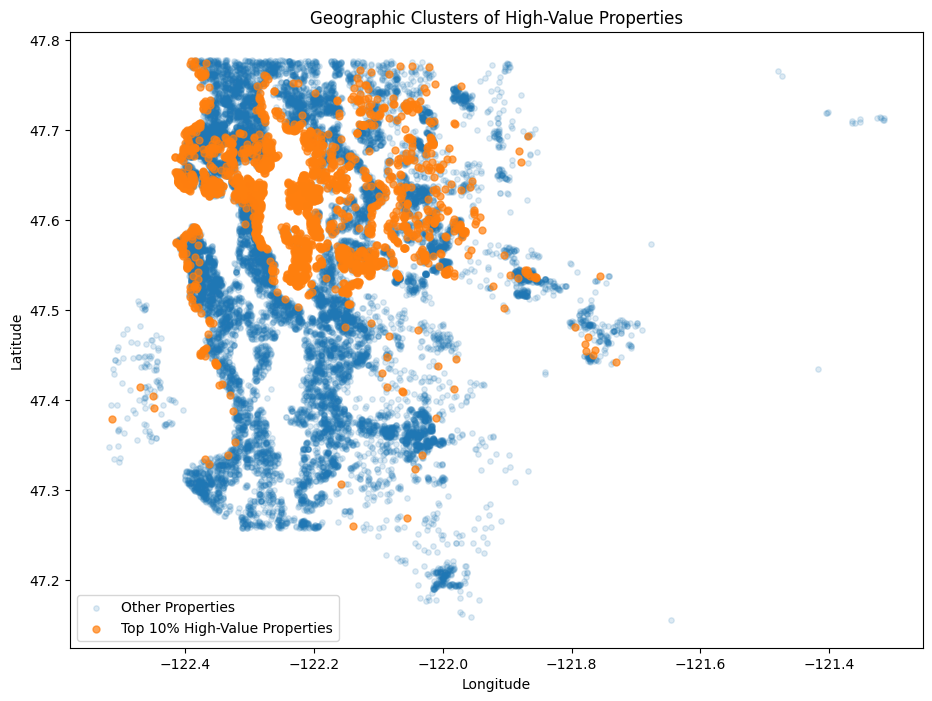

In [38]:
plt.figure(figsize=(11, 8))

normal = df[df["high_value"] == False]
high = df[df["high_value"] == True]

plt.scatter(
    normal["long"], normal["lat"],
    alpha=0.15, s=15,
    label="Other Properties"
)

plt.scatter(
    high["long"], high["lat"],
    alpha=0.7, s=25,
    label="Top 10% High-Value Properties"
)

plt.title("Geographic Clusters of High-Value Properties")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


In [39]:
df.groupby("high_value").agg(
    count=("price", "count"),
    median_price=("price", "median"),
    average_living_area=("sqft_living", "mean"),
    average_grade=("grade", "mean"),
    average_condition=("condition", "mean"),
    waterfront_share=("waterfront", "mean")
)

,count,median_price,average_living_area,average_grade,average_condition,waterfront_share
high_value,,,,,,
False,19436,425000.0,1915.086129,7.451739,3.404250,0.002521
True,2161,1156000.0,3566.449329,9.512263,3.459972,0.052753


## 6. Multivariable Property Valuation Analysis


In [40]:
if "property_age" not in df.columns:
    df["property_age"] = df["sale_year"] - df["yr_built"]

if "is_renovated" not in df.columns:
    df["is_renovated"] = (df["yr_renovated"] > 0).astype(int)

if "price_per_sqft_living" not in df.columns:
    df["price_per_sqft_living"] = df["price"] / df["sqft_living"]

if "price_per_sqft_lot" not in df.columns:
    df["price_per_sqft_lot"] = df["price"] / df["sqft_lot"]

df[[
    "property_age",
    "is_renovated",
    "price_per_sqft_living",
    "price_per_sqft_lot"
]].head()

,property_age,is_renovated,price_per_sqft_living,price_per_sqft_lot
0,59,0,188.050847,39.274336
1,63,1,209.338521,74.288870
2,82,0,233.766234,18.000000
3,49,0,308.163265,120.800000
4,28,0,303.571429,63.118812


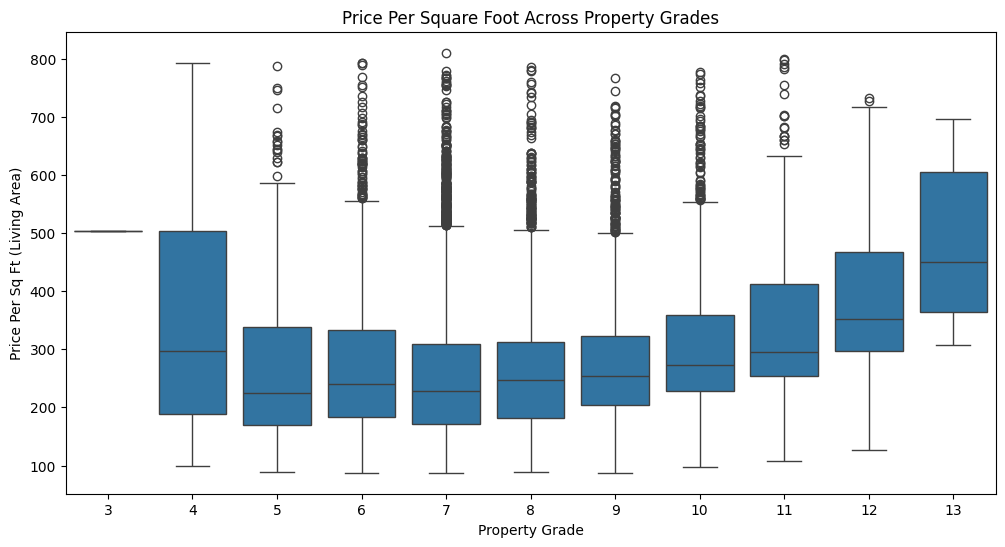

In [41]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    x="grade",
    y="price_per_sqft_living",
    data=df
)

plt.title("Price Per Square Foot Across Property Grades")
plt.xlabel("Property Grade")
plt.ylabel("Price Per Sq Ft (Living Area)")
plt.show()


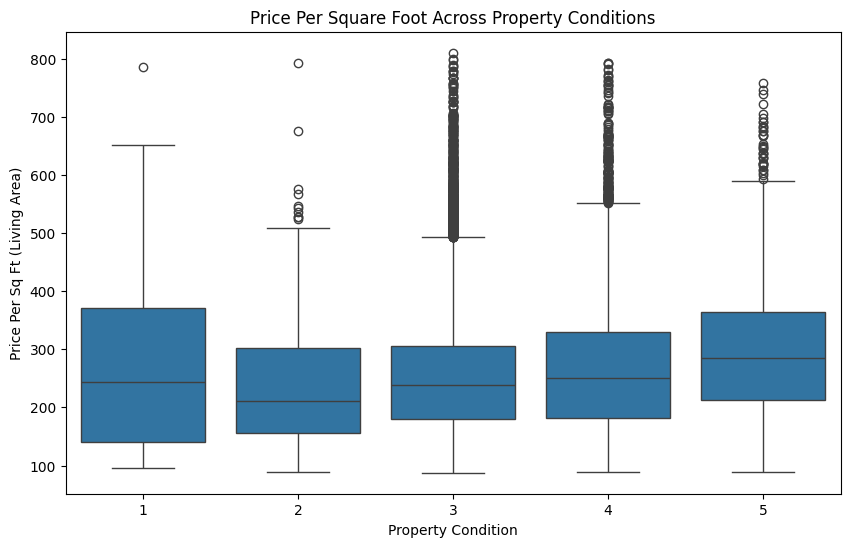

In [42]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="condition",
    y="price_per_sqft_living",
    data=df
)

plt.title("Price Per Square Foot Across Property Conditions")
plt.xlabel("Property Condition")
plt.ylabel("Price Per Sq Ft (Living Area)")
plt.show()


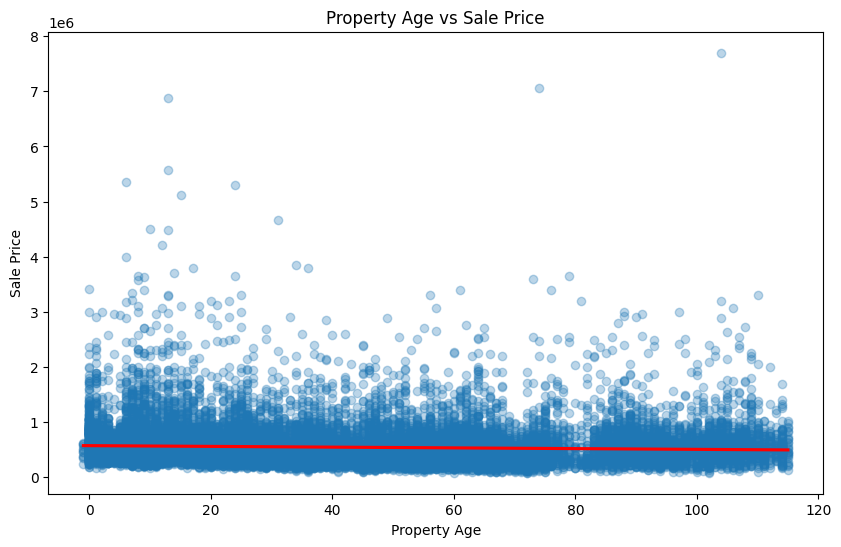

Correlation between property age and price: -0.053920205127834


In [43]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x="property_age",
    y="price",
    data=df,
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Property Age vs Sale Price")
plt.xlabel("Property Age")
plt.ylabel("Sale Price")
plt.show()

print(
    "Correlation between property age and price:",
    df["property_age"].corr(df["price"])
)


Average Sale Price by Renovation Status:
is_renovated
0    530473.143403
1    760379.029540
Name: price, dtype: float64


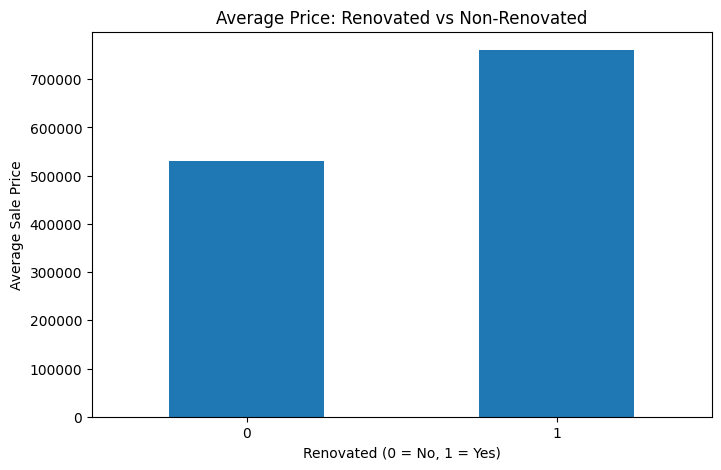

In [44]:
renovation_price = df.groupby("is_renovated")["price"].mean()

print("Average Sale Price by Renovation Status:")
print(renovation_price)

plt.figure(figsize=(8, 5))
renovation_price.plot(kind="bar")

plt.title("Average Price: Renovated vs Non-Renovated")
plt.xlabel("Renovated (0 = No, 1 = Yes)")
plt.ylabel("Average Sale Price")
plt.xticks(rotation=0)
plt.show()


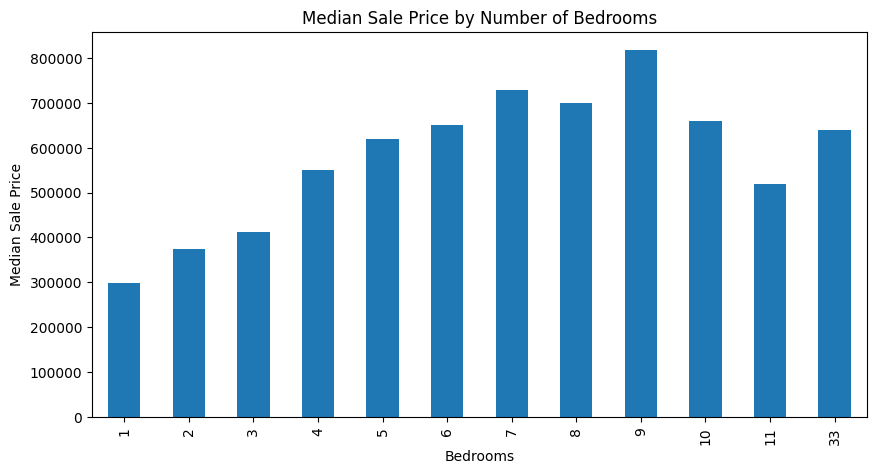

In [45]:
bedroom_price = df.groupby("bedrooms")["price"].median()

plt.figure(figsize=(10, 5))
bedroom_price.plot(kind="bar")

plt.title("Median Sale Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Median Sale Price")
plt.show()


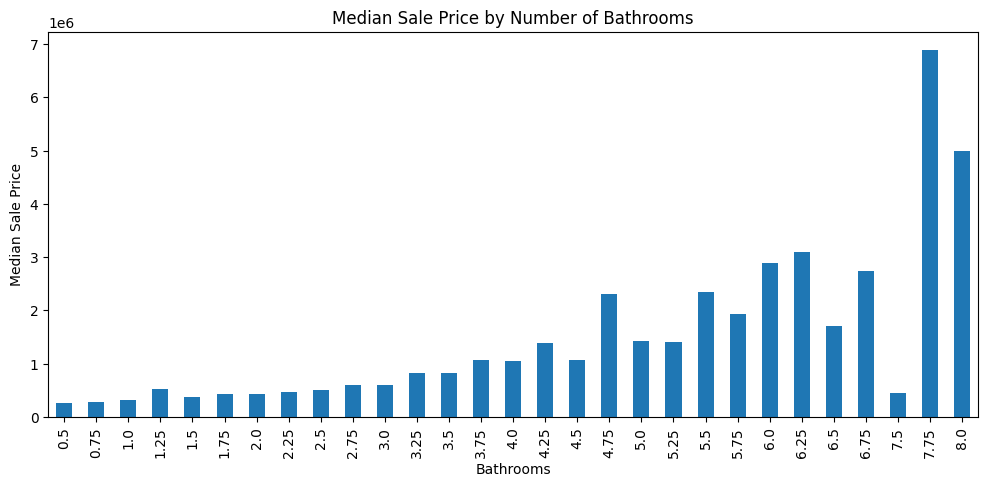

In [46]:
bathroom_price = df.groupby("bathrooms")["price"].median()

plt.figure(figsize=(12, 5))
bathroom_price.plot(kind="bar")

plt.title("Median Sale Price by Number of Bathrooms")
plt.xlabel("Bathrooms")
plt.ylabel("Median Sale Price")
plt.show()


## 7. Required Additional Visualizations


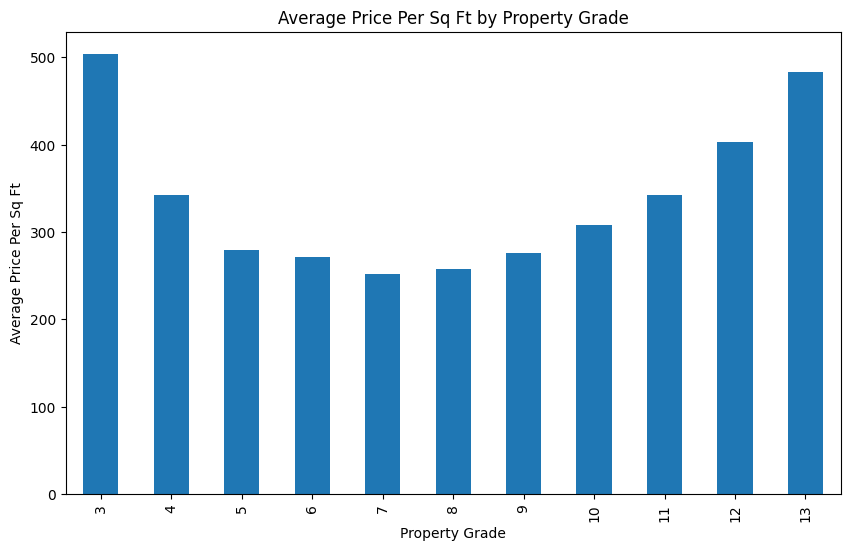

In [47]:
grade_ppsf = df.groupby("grade")["price_per_sqft_living"].mean()

plt.figure(figsize=(10, 6))
grade_ppsf.plot(kind="bar")

plt.title("Average Price Per Sq Ft by Property Grade")
plt.xlabel("Property Grade")
plt.ylabel("Average Price Per Sq Ft")
plt.show()


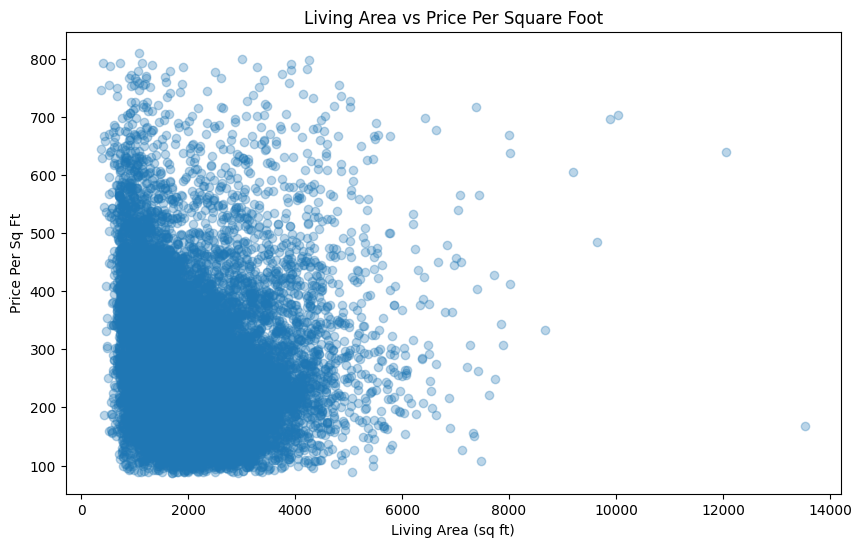

In [48]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["sqft_living"],
    df["price_per_sqft_living"],
    alpha=0.3
)

plt.title("Living Area vs Price Per Square Foot")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Price Per Sq Ft")
plt.show()


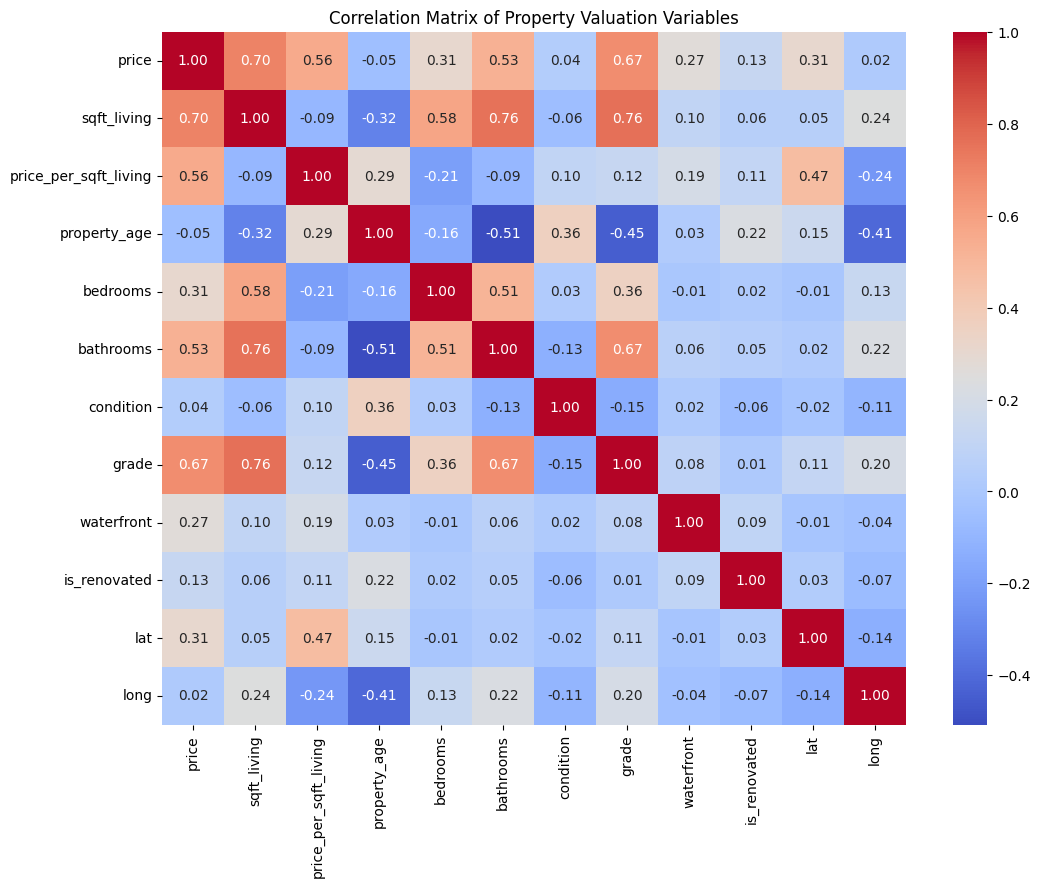

In [49]:
analysis_columns = [
    "price",
    "sqft_living",
    "price_per_sqft_living",
    "property_age",
    "bedrooms",
    "bathrooms",
    "condition",
    "grade",
    "waterfront",
    "is_renovated",
    "lat",
    "long"
]

correlation_matrix = df[analysis_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Property Valuation Variables")
plt.show()


## 8. Geographic Cluster Identification

In [50]:
GRID_SIZE = 0.02

df["lat_cluster"] = (df["lat"] / GRID_SIZE).round() * GRID_SIZE
df["long_cluster"] = (df["long"] / GRID_SIZE).round() * GRID_SIZE

cluster_summary = (
    df.groupby(["lat_cluster", "long_cluster"])
      .agg(
          sales=("price", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median"),
          high_value_properties=("high_value", "sum"),
          average_living_area=("sqft_living", "mean"),
          average_grade=("grade", "mean"),
          waterfront_share=("waterfront", "mean")
      )
      .reset_index()
)

cluster_summary = cluster_summary[
    cluster_summary["sales"] >= 10
]

top_clusters = cluster_summary.sort_values(
    ["median_price", "high_value_properties"],
    ascending=False
).head(15)

top_clusters

,lat_cluster,long_cluster,sales,average_price,median_price,high_value_properties,average_living_area,average_grade,waterfront_share
488,47.62,-122.24,19,2.345313e+06,2100000.0,19,4026.052632,9.894737,0.000000
568,47.68,-122.22,13,1.915485e+06,1875000.0,8,3620.384615,9.000000,0.153846
515,47.64,-122.24,18,2.095633e+06,1832500.0,15,3655.000000,9.166667,0.055556
415,47.56,-122.20,13,2.025073e+06,1730000.0,10,4399.230769,9.846154,0.230769
489,47.62,-122.22,62,1.922984e+06,1650000.0,60,3448.064516,9.241935,0.000000
516,47.64,-122.22,48,1.802853e+06,1590000.0,43,3561.979167,9.312500,0.020833
541,47.66,-122.26,10,1.639500e+06,1590000.0,8,3337.000000,8.900000,0.200000
514,47.64,-122.28,49,1.517203e+06,1425000.0,40,2959.387755,8.775510,0.000000
487,47.62,-122.28,56,1.441651e+06,1300000.0,43,3099.500000,9.089286,0.000000
387,47.54,-122.12,36,1.335826e+06,1290000.0,31,4612.222222,10.722222,0.000000


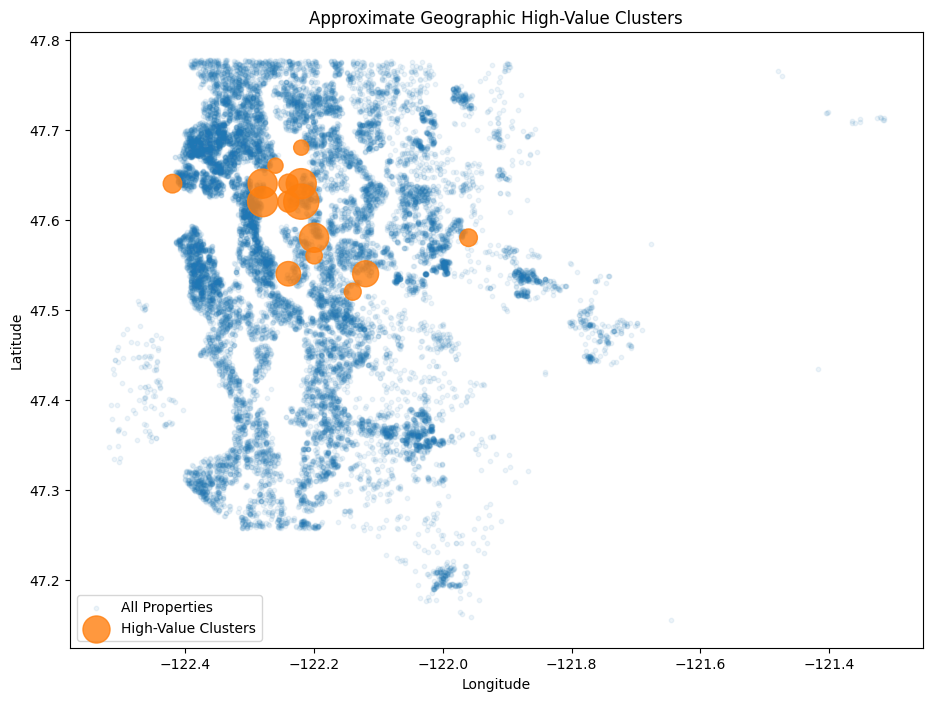

In [51]:
plt.figure(figsize=(11, 8))

plt.scatter(
    df["long"],
    df["lat"],
    alpha=0.08,
    s=10,
    label="All Properties"
)

plt.scatter(
    top_clusters["long_cluster"],
    top_clusters["lat_cluster"],
    s=top_clusters["high_value_properties"] * 10 + 40,
    alpha=0.8,
    label="High-Value Clusters"
)

plt.title("Approximate Geographic High-Value Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


## 9. Real-Estate Investment Summary Report

In [52]:
living_correlation = df["sqft_living"].corr(df["price"])
age_correlation = df["property_age"].corr(df["price"])

highest_grade = df.groupby("grade")["price"].median().idxmax()
highest_condition = df.groupby("condition")["price"].median().idxmax()

print("=" * 65)
print("REAL-ESTATE INVESTMENT SUMMARY")
print("=" * 65)

print("\n1. LIVING AREA AND PRICE")
print("Correlation:", round(living_correlation, 3))
print(
    "Larger living areas are generally associated with higher prices "
    "when the correlation is positive."
)

print("\n2. GRADE AND CONDITION")
print("Grade with highest median sale price:", highest_grade)
print("Condition with highest median sale price:", highest_condition)

print("\n3. WATERFRONT")
print("Observed mean waterfront premium:", round(mean_premium, 2), "%")
print("Observed median waterfront premium:", round(median_premium, 2), "%")

print("\n4. PROPERTY AGE")
print("Property age-price correlation:", round(age_correlation, 3))

print("\n5. GEOGRAPHY")
print(
    "The geographic scatter plots and cluster table identify areas "
    "containing concentrations of high-value sales."
)

if len(top_clusters) > 0:
    best = top_clusters.iloc[0]
    print(
        "Highest-ranked approximate cluster:",
        "Latitude =", round(best["lat_cluster"], 3),
        "Longitude =", round(best["long_cluster"], 3)
    )
    print("Cluster median price:", round(best["median_price"], 2))
    print("Average grade:", round(best["average_grade"], 2))
    print("Waterfront share:", round(best["waterfront_share"], 3))

print("\n6. INVESTMENT FACTORS")
print(
    "Living area, grade, condition, location, waterfront access, "
    "renovation status and property age should be evaluated together."
)

print("\n7. LIMITATIONS")
print(
    "These results show observed associations rather than causal effects. "
    "Extreme values, location differences and differences in property "
    "characteristics can influence the comparisons."
)


REAL-ESTATE INVESTMENT SUMMARY

1. LIVING AREA AND PRICE
Correlation: 0.702
Larger living areas are generally associated with higher prices when the correlation is positive.

2. GRADE AND CONDITION
Grade with highest median sale price: 13
Condition with highest median sale price: 5

3. WATERFRONT
Observed mean waterfront premium: 212.57 %
Observed median waterfront premium: 211.11 %

4. PROPERTY AGE
Property age-price correlation: -0.054

5. GEOGRAPHY
The geographic scatter plots and cluster table identify areas containing concentrations of high-value sales.
Highest-ranked approximate cluster: Latitude = 47.62 Longitude = -122.24
Cluster median price: 2100000.0
Average grade: 9.89
Waterfront share: 0.0

6. INVESTMENT FACTORS
Living area, grade, condition, location, waterfront access, renovation status and property age should be evaluated together.

7. LIMITATIONS
These results show observed associations rather than causal effects. Extreme values, location differences and differences in

## 10. Insights and Conclusion


In [53]:
price_correlations = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(ascending=False)
)

print("Numerical variables most positively associated with sale price:")
print(price_correlations)

print("\nCONCLUSION")
print(
    "1. Living area is an important property-size indicator associated "
    "with house price."
)
print(
    "2. Property grade and condition help explain differences in market "
    "valuation."
)
print(
    "3. Waterfront properties may show a substantial observed price "
    "premium."
)
print(
    "4. Geographic visualization reveals clusters of high-value sales "
    "that are not visible in simple summary statistics."
)
print(
    "5. Price per square foot provides a useful unit valuation measure "
    "for comparing differently sized properties."
)
print(
    "6. Real-estate evaluation should consider multiple characteristics "
    "together rather than relying on one variable."
)
print(
    "7. Further analysis can use multivariable regression or machine "
    "learning models for property-price prediction."
)


Numerical variables most positively associated with sale price:
sqft_living              0.701909
grade                    0.667922
price_per_sqft_living    0.555696
bathrooms                0.525905
bedrooms                 0.308794
lat                      0.306777
waterfront               0.266437
is_renovated             0.126073
condition                0.036025
long                     0.022092
property_age            -0.053920
Name: price, dtype: float64

CONCLUSION
1. Living area is an important property-size indicator associated with house price.
2. Property grade and condition help explain differences in market valuation.
3. Waterfront properties may show a substantial observed price premium.
4. Geographic visualization reveals clusters of high-value sales that are not visible in simple summary statistics.
5. Price per square foot provides a useful unit valuation measure for comparing differently sized properties.
6. Real-estate evaluation should consider multiple characteris